# Hourly PM2.5: actual vs predicted

Add `hourly_diagnostics.py` to `src/hazecast`. Keep the same hourly gold data, estimator parameters and package versions used for selection. This notebook reconstructs held-out predictions by refitting only the selected models on pre-test data. It never uses the production-fitted model to assess historical accuracy.

If matplotlib is missing, run `%pip install matplotlib` in a notebook cell and restart the kernel. Persist it in Docker requirements as well.


In [2]:
import sys, os, logging
from pathlib import Path

# Makes `import hazecast...` work whether this notebook is run from inside
# the Docker container (PYTHONPATH already set, see docker/pipeline.Dockerfile)
# or from a local `jupyter lab` with no PYTHONPATH set at all.
repo_root = Path.cwd()
if not (repo_root / "src" / "hazecast").exists():
    # notebook launched from notebooks/ instead of the repo root
    repo_root = repo_root.parent
src_path = str(repo_root / "src")
if src_path not in sys.path:
    sys.path.insert(0, src_path)

# Jupyter sets the kernel's cwd to wherever the .ipynb file lives (this
# notebook's own folder, when opened via JupyterLab's file browser) --
# NOT the repo root. That silently breaks anything that writes to a
# relative path, most importantly MLflow's default local artifact store
# (`./mlruns/`), which would otherwise land inside notebooks/ instead of
# next to data/ and mlflow.db. Pin cwd to the repo root explicitly so
# every relative path in every stage below resolves the same way it does
# when running `python -m hazecast....` from the repo root.
os.chdir(repo_root)

logging.basicConfig(level=logging.INFO, force=True)

import hazecast
print("hazecast package OK, repo root:", repo_root)

hazecast package OK, repo root: /app/src


In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from hazecast.config import GOLD_DIR, REPO_ROOT
from hazecast.hourly_diagnostics import backtest_selected_models, plot_actual_vs_predicted

hourly_gold = pd.read_parquet(GOLD_DIR / "hourly_features.parquet")
# Fits 18 selected models once; no six-candidate CV and no production writes.
predictions = backtest_selected_models(hourly_gold)
display(predictions.head())


,as_of_time,forecast_time,region,horizon_hours,model,actual_pm25,predicted_pm25,threshold,split,test_start,train_label_end,n_train
0,2024-04-15 05:00:00+08:00,2024-04-15 11:00:00+08:00,central,6,xgboost_q85,7.0,19.428164,56.0,final_test,2024-04-15T05:00:00+08:00,2024-04-15T04:00:00+08:00,88000
1,2024-04-15 06:00:00+08:00,2024-04-15 12:00:00+08:00,central,6,xgboost_q85,7.0,20.942961,56.0,final_test,2024-04-15T05:00:00+08:00,2024-04-15T04:00:00+08:00,88000
2,2024-04-15 07:00:00+08:00,2024-04-15 13:00:00+08:00,central,6,xgboost_q85,11.0,18.269106,56.0,final_test,2024-04-15T05:00:00+08:00,2024-04-15T04:00:00+08:00,88000
3,2024-04-15 08:00:00+08:00,2024-04-15 14:00:00+08:00,central,6,xgboost_q85,9.0,17.004822,56.0,final_test,2024-04-15T05:00:00+08:00,2024-04-15T04:00:00+08:00,88000
4,2024-04-15 09:00:00+08:00,2024-04-15 15:00:00+08:00,central,6,xgboost_q85,4.0,14.518891,56.0,final_test,2024-04-15T05:00:00+08:00,2024-04-15T04:00:00+08:00,88000


## Central, +6 hours — full saved holdout
The comparison uses forecast timestamps, with predicted and observed values referring to the same future hour.


/app/reports/central_h6_actual_vs_predicted_20240415_20261017.png
{'mae': 7.802060727697384, 'rmse': 10.95593193104258, 'f2': 0.6903248587570622, 'tp': 391, 'fp': 125, 'fn': 188, 'n_test': 21955, 'n_elevated': 579, 'mae_elevated': 30.436933886407775}


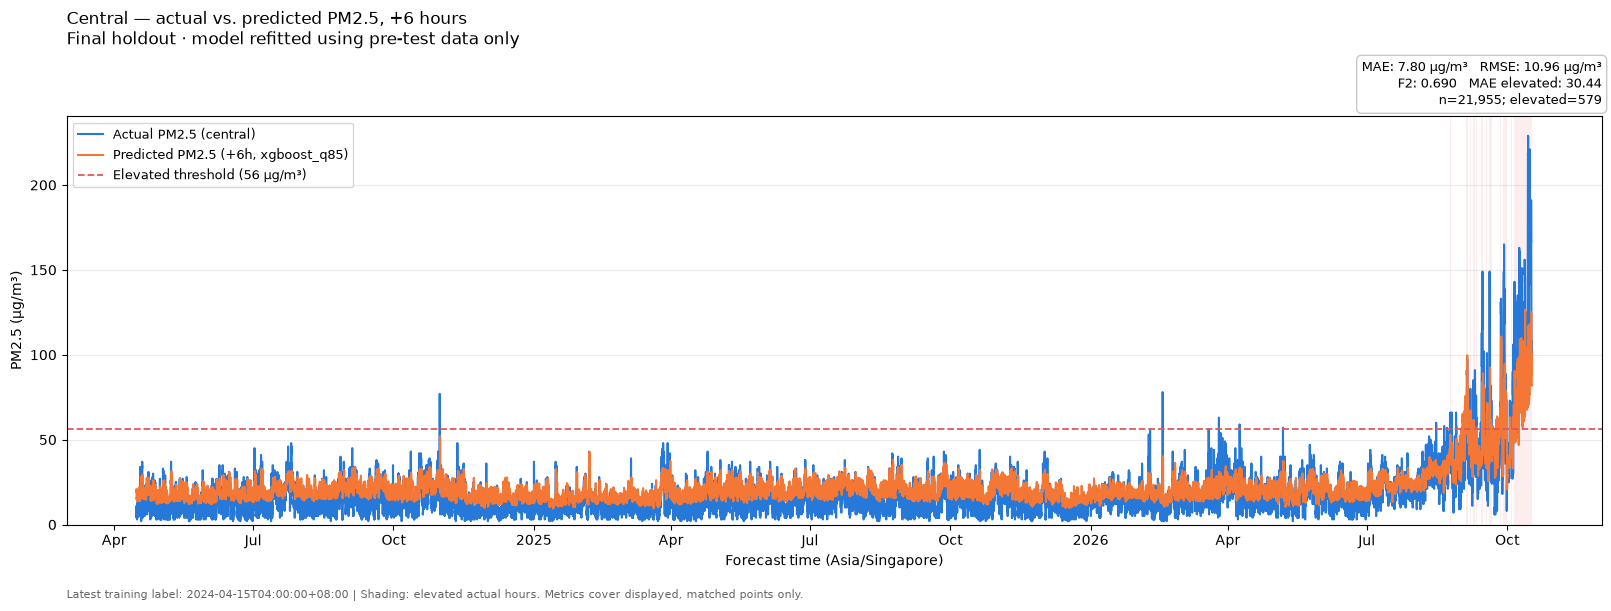

In [4]:
fig, metrics, path = plot_actual_vs_predicted(
    predictions, target="central", horizon=6,
)
print(path)
print(metrics)
plt.show()


## Optional: August 2026
Only run this if August is covered by the saved final holdout. Start is inclusive and end exclusive.


In [ ]:
# fig, metrics, path = plot_actual_vs_predicted(
#     predictions, target="central", horizon=6,
#     start="2026-08-01", end="2026-09-01",
# )
# print(path)
# plt.show()


## Save all 18 charts and a metric summary
Charts show the selected model for each region/horizon. All use final-test data only.


In [5]:
rows = []
for (target, horizon), group in predictions.groupby(["region", "horizon_hours"]):
    fig, metrics, path = plot_actual_vs_predicted(
        predictions, target=target, horizon=int(horizon),
    )
    rows.append({"region": target, "horizon_hours": int(horizon),
                 "model": group["model"].iloc[0], **metrics, "chart": str(path)})
    plt.close(fig)

summary = pd.DataFrame(rows)
summary.to_csv(REPO_ROOT / "reports" / "hourly_actual_vs_predicted_metrics.csv", index=False)
display(summary)


,region,horizon_hours,model,mae,rmse,f2,tp,fp,fn,n_test,n_elevated,mae_elevated,chart
0,central,6,xgboost_q85,7.802061,10.955932,0.690325,391,125,188,21955,579,30.436934,/app/reports/central_h6_actual_vs_predicted_20...
1,central,12,xgboost_q85,8.831273,13.417358,0.466598,271,293,314,21955,585,42.107875,/app/reports/central_h12_actual_vs_predicted_2...
2,central,24,xgboost_q85,9.024114,14.181729,0.318214,181,275,416,21955,597,47.011831,/app/reports/central_h24_actual_vs_predicted_2...
3,east,6,xgboost_q85,8.278898,10.356744,0.799550,355,177,67,21955,422,21.752010,/app/reports/east_h6_actual_vs_predicted_20240...
4,east,12,xgboost_q85,9.070749,11.971345,0.631271,302,378,126,21955,428,30.090362,/app/reports/east_h12_actual_vs_predicted_2024...
5,east,24,xgboost_q85,9.473615,13.667447,0.464135,220,390,220,21955,440,38.816836,/app/reports/east_h24_actual_vs_predicted_2024...
6,national,6,xgboost_q85,6.143117,8.387162,0.811531,335,189,50,21955,385,21.418267,/app/reports/national_h6_actual_vs_predicted_2...
7,national,12,xgboost_q85,7.435951,12.379076,0.561748,252,427,139,21955,391,32.408176,/app/reports/national_h12_actual_vs_predicted_...
8,national,24,xgboost_q85,7.288813,11.431237,0.462243,202,371,201,21955,403,38.752275,/app/reports/national_h24_actual_vs_predicted_...
9,north,6,xgboost_q85,8.811599,10.941943,0.737606,244,266,42,21955,286,18.414472,/app/reports/north_h6_actual_vs_predicted_2024...
